# Notebook 05 ? Moteur de Stress Testing
## Application des sc?narios actifs ? ECL Stress?e

**Objectif :** Appliquer les sc?narios actifs au portefeuille et calculer
l'ECL stress?e. Analyser l'impact sur PD, LGD, EAD et la migration de stage.

| Sc?nario | Choc Principal | Calibration |
|---|---|---|
| Adverse / Severe | PIB, ch?mage et spreads | Stress r?glementaire |
| Choc Taux | Fed Funds? (+3pp) | Stress taux |
| Choc March? 2018 | Taux et spreads sous tension | Test historique |
| Crise 2008 | Combin? FRED r?el | Calibr? historique |
| COVID-19 | Ch?mage extr?me, PIB en contraction | Test historique |


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Tester plusieurs scenarios de crise et mesurer la perte/provision attendue a 1 an.

**Lecture expert bancaire**  
Une crise historique doit etre verrouillee; seul un scenario personnalise est modifiable. Le resultat central est: perte Y1, ECL, PD/LGD/EAD et decision de resistance.

**Sorties attendues**  
stress_ecl_summary.csv, one_year_stress_decision_matrix.csv.

**Transition logique**  
Le notebook 06 traduit ces pertes en impact CET1, shortfall et actions de management.

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
from pathlib import Path

plt.rcParams['figure.figsize'] = (13, 5)
sns.set_style('whitegrid')

OUTPUT_DIR = Path('../outputs')
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'

print('Imports OK')


Imports OK


---
## 1. Chargement des modèles et données


In [2]:
from src.data_prep import get_pd_features
from src.stress_scenarios import SCENARIOS, SCENARIO_LABELS, SCENARIO_COLORS

# Dataset nettoyé + ECL baseline
df = pd.read_parquet(OUTPUT_DIR / 'loan_clean.parquet')
df_ecl = pd.read_parquet(OUTPUT_DIR / 'ecl_baseline.parquet')

# Reconstruire le df complet avec ECL baseline
df['PD_pred']   = df_ecl['PD_pred'].values
df['ECL_ifrs9'] = df_ecl['ECL_ifrs9'].values

features = get_pd_features(df)

# Charger le modèle PD champion
pd_models = {f.stem.replace('pd_model_', ''): joblib.load(f)
              for f in MODELS_DIR.glob('pd_model_*.pkl')}

# Sélectionner le champion (AUC le plus élevé)
try:
    results_df = pd.read_csv(MODELS_DIR / 'pd_model_comparison.csv', index_col=0)
    champion = results_df['AUC-ROC'].idxmax().lower()
except:
    champion = 'xgboost' if 'xgboost' in pd_models else list(pd_models.keys())[0]

pd_champion = pd_models[champion]
print(f'Modèle PD champion : {champion}')

# Charger les modèles satellites
sat_pd_models    = joblib.load(MODELS_DIR / 'satellite_pd_models.pkl')
sat_pd_features  = joblib.load(MODELS_DIR / 'satellite_pd_features.pkl')

# Champion satellite
try:
    sat_results = pd.read_csv(MODELS_DIR / 'satellite_pd_comparison.csv', index_col=0)
    sat_champion = sat_results['RMSE'].idxmin()
except:
    sat_champion = 'OLS'
print(f'Modèle satellite champion : {sat_champion}')

ecl_baseline = df['ECL_ifrs9'].sum() / 1e6
print(f'\nECL Baseline : ${ecl_baseline:,.2f} M')


Modèle PD champion : randomforest
Modèle satellite champion : Ridge

ECL Baseline : $3,803.04 M


---
## 2. Application des 3 scénarios de stress


In [3]:
from src.stress_scenarios import compute_stress_ecl, ACTIVE_STRESS_SCENARIOS

scenarios_to_run = ACTIVE_STRESS_SCENARIOS

print('=== Application des Scénarios de Stress ===')
stressed_results, summary_df = compute_stress_ecl(
    df, pd_champion, features,
    sat_pd_models, sat_pd_features, sat_champion,
    scenarios=scenarios_to_run,
)

print('\n=== Résumé ===')
display(summary_df)


=== Application des Scénarios de Stress ===

→ Scénario : Adverse
  ECL stressed : $7,764.1 M (×2.04 vs baseline)

→ Scénario : Severe
  ECL stressed : $8,431.2 M (×2.22 vs baseline)

→ Scénario : Choc Taux
  ECL stressed : $8,726.4 M (×2.29 vs baseline)

→ Scénario : Choc Marche 2018
  ECL stressed : $4,132.8 M (×1.09 vs baseline)

→ Scénario : Inflation Ukraine 2022
  ECL stressed : $6,252.5 M (×1.64 vs baseline)

→ Scénario : Crise 2008
  ECL stressed : $9,589.2 M (×2.52 vs baseline)

→ Scénario : Crise COVID-19
  ECL stressed : $10,043.0 M (×2.64 vs baseline)

✓ Résultats sauvegardés : C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\stress_ecl_summary.csv

=== Résumé ===


,Scenario,ECL_stressed_M$,ECL_baseline_M$,ΔECL_M$,ECL_lift,Coverage_%,PD_baseline_%,PD_stressed_%,PD_final_lift,PD_model_lift,PD_floor_lift,Severity_score,LGD_stressed_%,EAD_Mrd$,Coherent_stress
0,Adverse,7764.06,3803.04,3961.03,2.04,22.83,45.27,83.22,2.087,2.087,1.597,0.332,66.25,35.19,True
1,Severe,8431.24,3803.04,4628.20,2.22,24.79,45.27,88.57,2.464,2.464,1.877,0.487,67.57,35.70,True
2,Choc Taux,8726.36,3803.04,4923.32,2.29,25.66,45.27,86.08,2.269,2.269,1.479,0.266,72.48,35.36,True
3,Choc Marche 2018,4132.79,3803.04,329.75,1.09,12.15,45.27,48.33,1.068,1.068,1.043,0.024,60.39,34.00,True
4,Inflation Ukraine 2022,6252.47,3803.04,2449.43,1.64,18.39,45.27,66.06,1.469,1.469,1.238,0.133,66.28,34.55,True
5,Crise 2008,9589.22,3803.04,5786.18,2.52,28.20,45.27,93.37,3.106,3.106,2.616,0.898,73.34,36.04,True
6,Crise COVID-19,10042.99,3803.04,6239.95,2.64,29.53,45.27,96.10,3.841,3.841,3.112,1.173,71.82,37.64,True


## 2.b Comparaison des moteurs de stress testing

Am?lioration expert : on ne retient pas un seul moteur par d?faut. On compare plusieurs approches concurrentes puis on s?lectionne un champion selon backtesting, coh?rence ?conomique, stabilit?, pr?cision ECL et interpr?tabilit?.


In [4]:
from src.stress_model_comparison import compare_stress_testing_models
from src.stress_scenarios import SCENARIO_2008

print('=== Comparaison des moteurs de stress testing ===')
stress_model_scores, stress_champion = compare_stress_testing_models(
    df,
    scenario=SCENARIO_2008,
    scenario_name='crisis_2008',
    satellite_model=sat_pd_models,
    satellite_features=sat_pd_features,
    satellite_champion=sat_champion,
    save=True,
)

print(f'Modele champion retenu : {stress_champion}')
display(stress_model_scores)


=== Comparaison des moteurs de stress testing ===
Modele champion retenu : deterministic_sensitivity


,model_name,ECL_stressed_M$,ECL_lift,PD_baseline_%,PD_stressed_%,PD_lift,LGD_stressed_%,EAD_stressed_M$,observed_DR_error,economic_coherent,backtesting_score,economic_score,temporal_stability_score,ecl_precision_score,interpretability_score,final_score
0,deterministic_sensitivity,9323.616,2.4516,45.274,90.112,1.9904,73.34,36044.461,0.833419,True,0.037677,1.0,0.85,0.037677,0.95,0.529455
2,markov_stage_migration,12966.041,3.4094,45.274,90.112,1.9904,73.34,36044.461,0.833419,True,0.037677,1.0,0.85,0.037677,0.85,0.514455
4,hybrid_satellite_markov_floor,13174.918,3.4643,45.274,93.375,2.0624,73.34,36044.461,0.866049,True,0.000000,1.0,0.85,0.000000,0.80,0.490000
3,ml_macro_conditioned,9230.971,2.4273,45.274,88.987,1.9655,73.34,36044.461,0.822166,True,0.050670,1.0,0.85,0.050670,0.55,0.475302
1,satellite_macro,9589.220,2.5215,45.274,93.375,2.0624,73.34,36044.461,0.866049,True,0.000000,1.0,0.85,0.000000,0.70,0.475000


---
## 3. Comparaison ECL Baseline vs Stressée


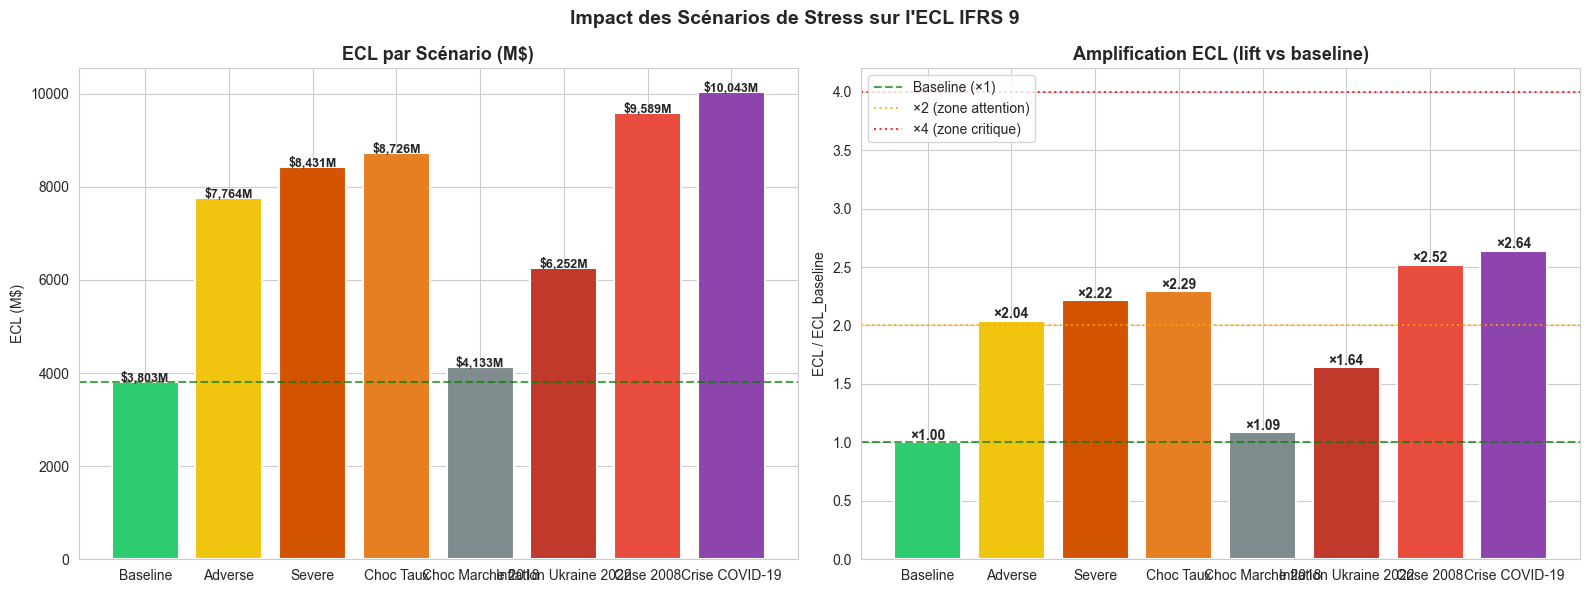

In [5]:
# Bar chart comparatif ECL
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ECL total par scénario
ecl_vals = [ecl_baseline] + [r['ECL_stressed'].sum()/1e6 for r in stressed_results.values()]
sc_names = ['Baseline'] + [SCENARIO_LABELS[k] for k in stressed_results.keys()]
sc_colors = ['#2ecc71'] + [SCENARIO_COLORS[k] for k in stressed_results.keys()]

bars = axes[0].bar(sc_names, ecl_vals, color=sc_colors, edgecolor='white', linewidth=1.5)
axes[0].axhline(ecl_baseline, color='green', linestyle='--', alpha=0.7, label='Baseline')
for bar, v in zip(bars, ecl_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                  f'${v:,.0f}M', ha='center', fontweight='bold', fontsize=9)
axes[0].set_title('ECL par Scénario (M$)', fontweight='bold', fontsize=13)
axes[0].set_ylabel('ECL (M$)')

# Lift ECL (ratio vs baseline)
lifts = [1.0] + [r['ECL_stressed'].sum() / (df['ECL_ifrs9'].sum() + 1e-9)
                  for r in stressed_results.values()]
bars2 = axes[1].bar(sc_names, lifts, color=sc_colors, edgecolor='white', linewidth=1.5)
axes[1].axhline(1.0, color='green', linestyle='--', alpha=0.7, label='Baseline (×1)')
axes[1].axhline(2.0, color='orange', linestyle=':', alpha=0.8, label='×2 (zone attention)')
axes[1].axhline(4.0, color='red', linestyle=':', alpha=0.8, label='×4 (zone critique)')
for bar, v in zip(bars2, lifts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                  f'×{v:.2f}', ha='center', fontweight='bold', fontsize=10)
axes[1].set_title('Amplification ECL (lift vs baseline)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('ECL / ECL_baseline')
axes[1].legend(loc='upper left')

plt.suptitle('Impact des Scénarios de Stress sur l\'ECL IFRS 9', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_26_stress_ecl_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


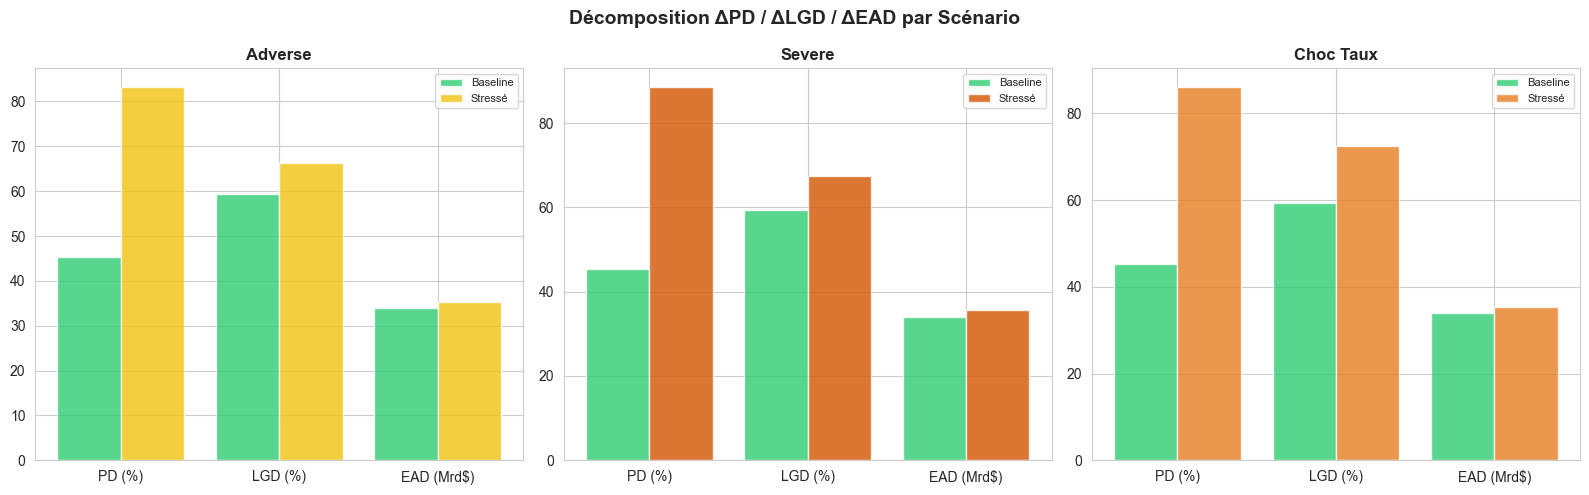

In [6]:
# Decomposition des chocs : ΔPD, ΔLGD, ΔEAD par scénario
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (sc_name, df_s) in enumerate(stressed_results.items()):
    if idx >= 3:
        break

pd_base = df['PD_pred'].mean() * 100
for ax, (sc_name, df_s) in zip(axes, stressed_results.items()):
    pd_s   = df_s['PD_stressed'].mean() * 100
    lgd_b  = df['LGD'].mean() * 100
    lgd_s  = df_s['LGD_stressed'].mean() * 100
    ead_b  = df['EAD'].sum() / 1e9
    ead_s  = df_s['EAD_stressed'].sum() / 1e9
    
    components = ['PD (%)', 'LGD (%)', 'EAD (Mrd$)']
    base_vals = [pd_base, lgd_b, ead_b]
    stress_vals = [pd_s, lgd_s, ead_s]
    
    x = np.arange(3)
    ax.bar(x - 0.2, base_vals, 0.4, label='Baseline', color='#2ecc71', alpha=0.8)
    ax.bar(x + 0.2, stress_vals, 0.4, label='Stressé',
            color=SCENARIO_COLORS[sc_name], alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(components)
    ax.set_title(SCENARIO_LABELS[sc_name], fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Décomposition ΔPD / ΔLGD / ΔEAD par Scénario',
              fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_27_components_stress.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 4. ECL Stressée par Grade


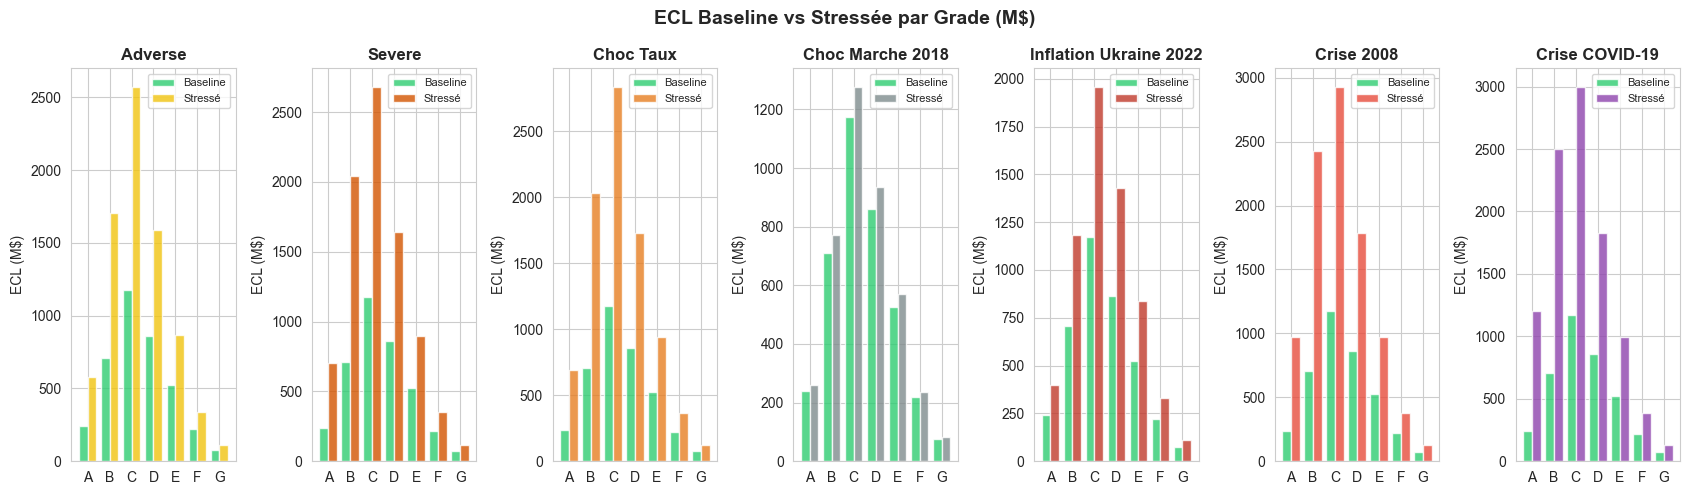

In [7]:
if 'grade' in df.columns:
    grades = ['A','B','C','D','E','F','G']
    palette = sns.color_palette('RdYlGn_r', 7)
    
    ecl_grade_baseline = df.groupby('grade')['ECL_ifrs9'].sum().reindex(grades) / 1e6
    
    fig, axes = plt.subplots(1, len(stressed_results), figsize=(17, 5))
    if not hasattr(axes, '__len__'):
        axes = [axes]
    
    for ax, (sc_name, df_s) in zip(axes, stressed_results.items()):
        ecl_grade_s = df_s.groupby('grade')['ECL_stressed'].sum().reindex(grades) / 1e6
        
        x = np.arange(len(grades))
        ax.bar(x - 0.2, ecl_grade_baseline, 0.4, label='Baseline',
                color='#2ecc71', alpha=0.8, edgecolor='white')
        ax.bar(x + 0.2, ecl_grade_s, 0.4, label='Stressé',
                color=SCENARIO_COLORS[sc_name], alpha=0.8, edgecolor='white')
        ax.set_xticks(x)
        ax.set_xticklabels(grades)
        ax.set_title(SCENARIO_LABELS[sc_name], fontweight='bold')
        ax.set_ylabel('ECL (M$)')
        ax.legend(fontsize=8)
    
    plt.suptitle('ECL Baseline vs Stressée par Grade (M$)',
                  fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_28_ecl_by_grade_stress.png', dpi=150, bbox_inches='tight')
    plt.show()


---
## 5. Migration de Stage sous Stress


In [8]:
from src.stress_scenarios import compute_stage_migration

migration_stats_all = []
transitions_all = {}

for sc_name, df_s in stressed_results.items():
    df_s_migrated, stats, transition = compute_stage_migration(df, df_s, sc_name)
    migration_stats_all.append(stats)
    transitions_all[sc_name] = transition

migration_df = pd.DataFrame(migration_stats_all).set_index('scenario')
print('\n=== Tableau de Migration de Stage ===')
display(migration_df)



Migration Stage [adverse] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 99.7% (25,549 prêts)

Migration Stage [severe] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 99.9% (25,614 prêts)

Migration Stage [rate_shock] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 99.8% (25,583 prêts)

Migration Stage [market_2018] :
  Stage 1 → Stage 2 : 0.0% (0 prêts)
  Stage 2 → Stage 3 : 94.8% (24,292 prêts)

Migration Stage [ukraine_2022] :
  Stage 1 → Stage 2 : 0.0% (0 prêts)
  Stage 2 → Stage 3 : 98.0% (25,126 prêts)

Migration Stage [crisis_2008] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 100.0% (25,634 prêts)

Migration Stage [covid_2020] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 100.0% (25,634 prêts)

=== Tableau de Migration de Stage ===


,S1_to_S1_%,S1_to_S2_%,S2_to_S2_%,S2_to_S3_%,S3_maintained,n_migrated_S2,n_migrated_S3
scenario,,,,,,,
adverse,39.4,60.6,0.3,99.7,100.0,1196355,25549
severe,39.4,60.6,0.1,99.9,100.0,1196355,25614
rate_shock,39.4,60.6,0.2,99.8,100.0,1196355,25583
market_2018,100.0,0.0,5.2,94.8,100.0,0,24292
ukraine_2022,100.0,0.0,2.0,98.0,100.0,0,25126
crisis_2008,39.4,60.6,0.0,100.0,100.0,1196355,25634
covid_2020,39.4,60.6,0.0,100.0,100.0,1196355,25634


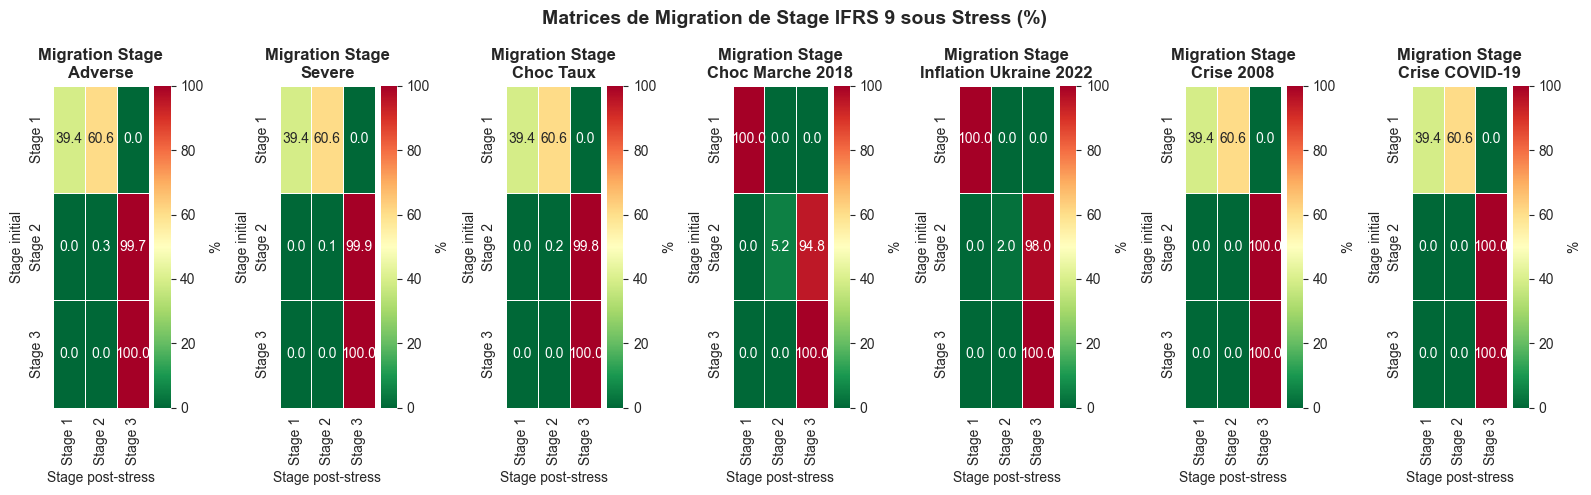

In [9]:
# Heatmaps de migration par scénario
fig, axes = plt.subplots(1, len(transitions_all), figsize=(16, 5))
if not hasattr(axes, '__len__'):
    axes = [axes]

for ax, (sc_name, transition) in zip(axes, transitions_all.items()):
    t_plot = transition.reindex(index=[1,2,3], columns=[1,2,3], fill_value=0)
    stage_labs = ['Stage 1', 'Stage 2', 'Stage 3']
    sns.heatmap(t_plot, annot=True, fmt='.1f', cmap='RdYlGn_r',
                vmin=0, vmax=100, ax=ax, linewidths=0.5,
                xticklabels=stage_labs, yticklabels=stage_labs,
                cbar_kws={'label': '%'})
    ax.set_title(f'Migration Stage\n{SCENARIO_LABELS[sc_name]}', fontweight='bold')
    ax.set_xlabel('Stage post-stress')
    ax.set_ylabel('Stage initial')

plt.suptitle('Matrices de Migration de Stage IFRS 9 sous Stress (%)',
              fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_29_stage_migration.png', dpi=150, bbox_inches='tight')
plt.show()



Migration Stage [crisis_2008] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 100.0% (25,634 prêts)

Migration Stage [crisis_2008] :
  Stage 1 → Stage 2 : 60.6% (1,196,355 prêts)
  Stage 2 → Stage 3 : 100.0% (25,634 prêts)


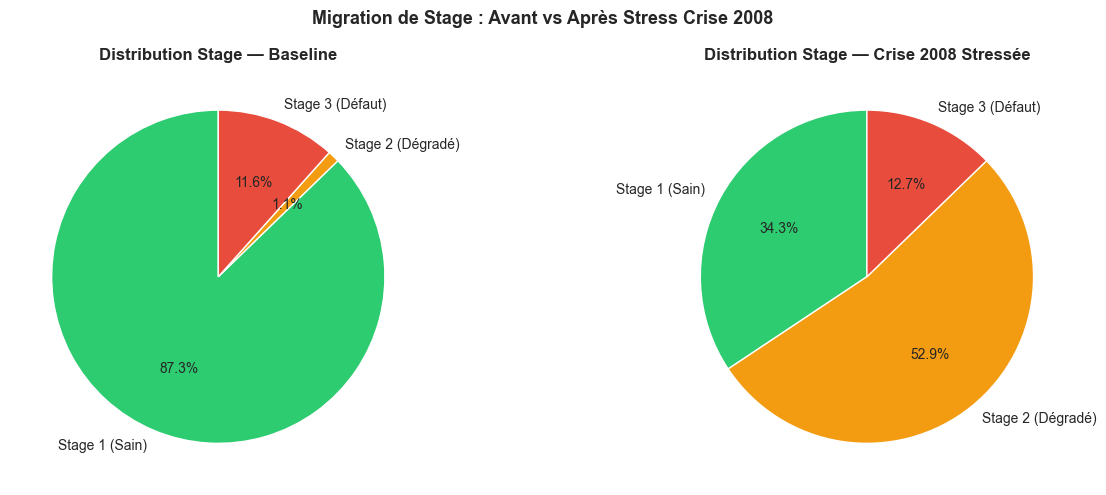


=== Notebook 04 terminé ===
Résultats sauvegardés : outputs/results/stress_ecl_summary.csv


In [10]:
# Distribution Stage baseline vs stressée (Scénario 2008)
sc_2008 = stressed_results.get('crisis_2008', list(stressed_results.values())[-1])
_, _, transition_2008 = compute_stage_migration(df, sc_2008, 'crisis_2008')
df_stage_2008, _, _ = compute_stage_migration(df, sc_2008, 'crisis_2008')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stage_labels = {1: 'Stage 1 (Sain)', 2: 'Stage 2 (Dégradé)', 3: 'Stage 3 (Défaut)'}
stage_colors = ['#2ecc71', '#f39c12', '#e74c3c']

base_dist  = df['stage'].value_counts().sort_index()
stress_dist = df_stage_2008['stage_stressed'].value_counts().sort_index() \
    if 'stage_stressed' in df_stage_2008.columns else base_dist

axes[0].pie([base_dist.get(s, 0) for s in [1,2,3]],
            labels=[stage_labels[s] for s in [1,2,3]],
            autopct='%1.1f%%', colors=stage_colors, startangle=90)
axes[0].set_title('Distribution Stage — Baseline', fontweight='bold')

axes[1].pie([stress_dist.get(s, 0) for s in [1,2,3]],
            labels=[stage_labels[s] for s in [1,2,3]],
            autopct='%1.1f%%', colors=stage_colors, startangle=90)
axes[1].set_title('Distribution Stage — Crise 2008 Stressée', fontweight='bold')

plt.suptitle('Migration de Stage : Avant vs Après Stress Crise 2008',
              fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_30_stage_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Notebook 04 terminé ===')
print(f'Résultats sauvegardés : outputs/results/stress_ecl_summary.csv')


## Controle bancaire complementaire: matrice stress testing a 1 an

Cette table repond a la question centrale du stress testing: combien la banque
perd l'annee prochaine sous chaque crise, quel est le CET1 post-stress et quelle
action de management est requise.

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
stress_decision_path = ROOT / "outputs" / "results" / "one_year_stress_decision_matrix.csv"

if stress_decision_path.exists():
    stress_decision = pd.read_csv(stress_decision_path)
    display(stress_decision)
else:
    print("Sortie non disponible. Executer scripts/generate_banking_expert_review.py ou le notebook 08.")

## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.